# Cognifyz Data Analysis Internship — Level 1

## Data Analysis Internship Project

**Intern:** Anshuman Ray  
**Organization:** Cognifyz IT Solutions Pvt. Ltd.  
**Role:** Data Analysis Intern  
**Level:** Level 1 (Top Cuisines, City Analysis, Price Range Distribution, Online Delivery)

## 1. Internship Context

This project is part of the official **Cognifyz IT Solutions Data Analysis internship**. The internship focuses on practical hands-on work with a real-world restaurant dataset using the Python data science stack. The core skills exercised are:

- Data manipulation and cleaning with **pandas**
- Statistical analysis of distributions and averages
- Data visualization with **Matplotlib** and **Seaborn**
- Extracting actionable insights from raw data

The official task brief offers three levels and requires the intern to select **any two**. I have selected **Level 1** and **Level 2**. This notebook implements all four tasks of **Level 1** in full.

## 2. Level 1 Overview & Objectives

Level 1 introduces the dataset and covers basic analysis skills. It contains four tasks:

| Task | Title | Analytical Question |
|------|-------|--------------------|
| 1 | **Top Cuisines** | Which cuisines are most common, and what share of restaurants serve them? |
| 2 | **City Analysis** | Which city has the most restaurants and which has the best average rating? |
| 3 | **Price Range Distribution** | How are restaurants distributed across price ranges? |
| 4 | **Online Delivery** | What share of restaurants offer online delivery, and how do their ratings compare? |

The overall objective is to characterise the dataset: *what cuisines dominate, where restaurants concentrate, how price is distributed, and whether online-delivery capability relates to ratings.*

## 3. Dataset Overview

The dataset describes restaurants listed on a food-aggregator platform (Zomato). It contains restaurant-level records with identity, geographic, cuisine, cost, and rating information.

**Key column groups:**

- **Identity / location:** `Restaurant ID`, `Restaurant Name`, `Country Code`, `City`, `Address`, `Locality`, `Longitude`, `Latitude`
- **Offerings / cost:** `Cuisines`, `Average Cost for two`, `Currency`, `Has Table booking`, `Has Online delivery`, `Is delivering now`, `Switch to order menu`, `Price range`
- **Ratings / popularity:** `Aggregate rating`, `Rating color`, `Rating text`, `Votes`

In [1]:
# Standard data science libraries used throughout this notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sensible global style defaults for readable, consistent charts
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Suppress irrelevant warnings for a clean notebook
import warnings
warnings.filterwarnings('ignore')

print('Libraries imported successfully.')

Libraries imported successfully.


In [2]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current working directory:
d:\Cognifyz_Data_Analysis_Internship\Cognifyz-Data-Analysis\Level_1

Files and folders here:
['Cognifyz_Level_1_Data_Analysis.ipynb']


In [3]:
import os

print("Searching D: drive for Dataset.csv...\n")

found = []

for root, dirs, files in os.walk(r"D:\\"):
    if "Dataset.csv" in files:
        found.append(os.path.join(root, "Dataset.csv"))

print("Found files:")

if found:
    for path in found:
        print(path)
else:
    print("Dataset.csv was NOT found anywhere on the D: drive.")

Searching D: drive for Dataset.csv...

Found files:
D:\\Cognifyz_Data_Analysis_Internship\Cognifyz-Data-Analysis\data\Dataset.csv


In [4]:

from pathlib import Path
import pandas as pd

# Find the dataset in the project data folder
dataset_name = "Dataset_real.csv"

dataset_path = next(
    (
        folder / "data" / dataset_name
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "data" / dataset_name).is_file()
    ),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "Dataset_real.csv not found. Check the data folder."
    )

df = pd.read_csv(dataset_path, encoding="utf-8")

print("Dataset loaded successfully!")
print("Dataset path:", dataset_path)
print("Shape (rows, columns):", df.shape)

df.head()


Dataset loaded successfully!
Dataset path: d:\Cognifyz_Data_Analysis_Internship\Cognifyz-Data-Analysis\data\Dataset_real.csv
Shape (rows, columns): (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## 4. Initial Inspection

Before any analysis, we inspect the raw structure of the data — its size, columns, data types, and a sample of rows — so that every later step is grounded in what the data actually contains.

In [5]:
# First look at the top and bottom rows
df.head(5)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [6]:
df.tail(5)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
9546,5915730,Naml۱ Gurme,208,��stanbul,"Kemanke�� Karamustafa Pa��a Mahallesi, R۱ht۱m ...",Karak�_y,"Karak�_y, ��stanbul",28.977392,41.022793,Turkish,...,Turkish Lira(TL),No,No,No,No,3,4.1,Green,Very Good,788
9547,5908749,Ceviz A��ac۱,208,��stanbul,"Ko��uyolu Mahallesi, Muhittin ��st�_nda�� Cadd...",Ko��uyolu,"Ko��uyolu, ��stanbul",29.041297,41.009847,"World Cuisine, Patisserie, Cafe",...,Turkish Lira(TL),No,No,No,No,3,4.2,Green,Very Good,1034
9548,5915807,Huqqa,208,��stanbul,"Kuru�_e��me Mahallesi, Muallim Naci Caddesi, N...",Kuru�_e��me,"Kuru�_e��me, ��stanbul",29.034640,41.055817,"Italian, World Cuisine",...,Turkish Lira(TL),No,No,No,No,4,3.7,Yellow,Good,661
9549,5916112,A���k Kahve,208,��stanbul,"Kuru�_e��me Mahallesi, Muallim Naci Caddesi, N...",Kuru�_e��me,"Kuru�_e��me, ��stanbul",29.036019,41.057979,Restaurant Cafe,...,Turkish Lira(TL),No,No,No,No,4,4.0,Green,Very Good,901
9550,5927402,Walter's Coffee Roastery,208,��stanbul,"Cafea��a Mahallesi, Bademalt۱ Sokak, No 21/B, ...",Moda,"Moda, ��stanbul",29.026016,40.984776,Cafe,...,Turkish Lira(TL),No,No,No,No,2,4.0,Green,Very Good,591


In [7]:
# Column names, non-null counts, and data types in one view
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [8]:
# Summary statistics for the numerical columns
df.describe()

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


### Observations from the initial inspection

The `describe()` output already reveals things worth watching closely for the later tasks:

- `Aggregate rating` runs from a minimum of **0.0**. In this dataset a rating of **0.0** is paired with the rating text **"Not rated"** — it represents an *unrated* restaurant, not a genuinely bad rating. This matters for every rating calculation in this notebook.
- `Votes` is heavily right-skewed: the mean is well above the median, indicating a few very popular restaurants pull the average upward.
- `Longitude`/`Latitude` show a wide spread; some rows carry coordinates of exactly `(0, 0)`, which are invalid and excluded from geographic work in Level 2.

## 5. Data Quality Check

We now quantify the quality issues in the data before cleaning: missing values, duplicate rows, and the unique values of the key categorical columns used by the Level 1 tasks.

In [9]:
# Missing values per column
missing = df.isnull().sum()
missing_df = pd.DataFrame({'Column': missing.index, 'Missing': missing.values,
                           'Percent': (missing.values / len(df) * 100).round(2)})
missing_df[missing_df['Missing'] > 0]

,Column,Missing,Percent
9,Cuisines,9,0.09


In [10]:
# Duplicate rows
print('Number of duplicate rows:', df.duplicated().sum())

# Duplicate Restaurant IDs (a different kind of duplication)
print('Number of duplicate Restaurant IDs:', df['Restaurant ID'].duplicated().sum())

Number of duplicate rows: 0
Number of duplicate Restaurant IDs: 0


In [11]:
# Categorical columns relevant to Level 1 tasks
cat_cols = ['City', 'Price range', 'Has Online delivery']
for col in cat_cols:
    print('===', col, '===')
    print(df[col].value_counts().head(8).to_string())
    print()

=== City ===
City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Lucknow           21
Ahmedabad         21

=== Price range ===
Price range
1    4444
2    3113
3    1408
4     586

=== Has Online delivery ===
Has Online delivery
No     7100
Yes    2451



In [12]:
# Unrated restaurants: Aggregate rating == 0.0 with rating text 'Not rated'
unrated = df['Aggregate rating'] == 0.0
print('Restaurants with rating 0.0 (unrated):', unrated.sum())
print('Share of dataset:', round(unrated.sum() / len(df) * 100, 2), '%')

# Sanity check: do 0.0 ratings coincide with 'Not rated' rating text?
print('\nRating text among rating-0 rows:')
print(df.loc[unrated, 'Rating text'].value_counts().to_string())

Restaurants with rating 0.0 (unrated): 2148
Share of dataset: 22.49 %

Rating text among rating-0 rows:
Rating text
Not rated    2148


### Data-quality summary (before cleaning)

The checks above establish concrete data-quality facts used throughout this notebook:

1. **Only the `Cuisines` column contains missing values.** All other columns are complete.
2. **There are no exact duplicate rows** and **no duplicate `Restaurant ID`s** — each row is a distinct restaurant record.
3. **Some restaurants are unrated** (rating `0.0` / `"Not rated"`). These carry no real rating and are excluded from rating-average calculations.
4. The categorical columns are clean with consistent values (`Price range` in {1,2,3,4}, `Has Online delivery` in {Yes, No}).

Missing cuisine values will be handled explicitly within the cuisine tasks.

## 6. Data Cleaning

We perform only the cleaning needed for reliable analysis. The guiding principle is **transparency**: every decision is reported and no rows are silently dropped. The original `df` is left untouched; we build a cleaned working copy `clean_df`.

In [13]:
clean_df = df.copy()
rows_before = len(clean_df)

# 1) Flag unrated restaurants (rating 0.0) so rating-based analyses can exclude them
clean_df['is_rated'] = clean_df['Aggregate rating'] > 0

# 2) Cuisines: standardise whitespace but keep rows and missing values intact;
#    NaN is left as NaN and handled within the cuisine task explicitly.
clean_df['Cuisines'] = clean_df['Cuisines'].str.strip()

# 3) Strip leading/trailing whitespace from text categories to avoid miscounting
for col in ['City', 'Has Online delivery', 'Restaurant Name']:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].str.strip()
        
rows_after = len(clean_df)

print('Rows before cleaning:', rows_before)
print('Rows after cleaning: ', rows_after)
print('No rows were dropped (only standardised text and added a rated flag).')
print('\nBefore/after data-quality summary:')
print('  Missing Cuisines (before):', df['Cuisines'].isnull().sum())
print('  Missing Cuisines (after): ', clean_df['Cuisines'].isnull().sum())

Rows before cleaning: 9551
Rows after cleaning:  9551
No rows were dropped (only standardised text and added a rated flag).

Before/after data-quality summary:
  Missing Cuisines (before): 9
  Missing Cuisines (after):  9


### Cleaning decisions

- **No rows are dropped.** Cleaning only standardises text (strips whitespace) and adds a helper `is_rated` flag.
- **Missing `Cuisines` values are preserved** and handled explicitly within the cuisine analysis rather than silently discarded.
- **Unrated restaurants are flagged**, not deleted, so each task can choose the appropriate subset and report it.

---

# 7. Task 1 — Top Cuisines

## What we are trying to determine

We want to find the **three most common cuisines** in the dataset and the **percentage of restaurants that serve each of them**.

## Methodology

The `Cuisines` column stores **one or more cuisines per restaurant as a comma-separated string** — for example `"French, Japanese, Desserts"`. This is important: if we naively counted whole strings, we would treat that trio as a single cuisine and massively under-count French, Japanese and Desserts.

The correct approach is to **split each restaurant's cuisine string on the comma and unnest/explode**, so one restaurant contributes to the count of *each* cuisine it serves. 

**Calculating the Percentage:**
The percentage represents the **percentage of restaurants serving each cuisine**:
$$\text{Percentage} = \frac{\text{Number of restaurants serving that cuisine}}{\text{Total restaurants with cuisine information}} \times 100$$

Because a single restaurant can serve multiple cuisines simultaneously, these percentages reflect restaurant *coverage* and do **not** sum to 100%.

In [14]:
# Work on the rows that actually have cuisine information
cuisine_rows = clean_df[clean_df['Cuisines'].notna()].copy()
total_restaurants_with_cuisines = len(cuisine_rows)

print('Total restaurants with cuisine info (denominator):', total_restaurants_with_cuisines)
print('Restaurants excluded (missing Cuisines):', len(clean_df) - total_restaurants_with_cuisines)

# Split each restaurant's cuisine string on the comma and strip whitespace
cuisine_exploded = cuisine_rows.copy()
cuisine_exploded['Cuisine_list'] = cuisine_exploded['Cuisines'].str.split(',')
cuisine_exploded = cuisine_exploded.explode('Cuisine_list')
cuisine_exploded['Cuisine_list'] = cuisine_exploded['Cuisine_list'].str.strip()

# Count restaurants serving each cuisine
cuisine_counts = cuisine_exploded['Cuisine_list'].value_counts()

# Percentage of RESTAURANTS serving each cuisine (denominator = total restaurants with cuisine info)
cuisine_pct = (cuisine_counts / total_restaurants_with_cuisines * 100).round(2)

# Build the top-3 table
top3 = pd.DataFrame({
    'Cuisine': cuisine_counts.index[:3],
    'Restaurants_serving': cuisine_counts.values[:3],
    'Percent_of_restaurants': cuisine_pct.values[:3]
})
print('\nTOP 3 MOST COMMON CUISINES (Percentage of Restaurants):')
top3

Total restaurants with cuisine info (denominator): 9542
Restaurants excluded (missing Cuisines): 9

TOP 3 MOST COMMON CUISINES (Percentage of Restaurants):


,Cuisine,Restaurants_serving,Percent_of_restaurants
0,North Indian,3960,41.50
1,Chinese,2735,28.66
2,Fast Food,1986,20.81


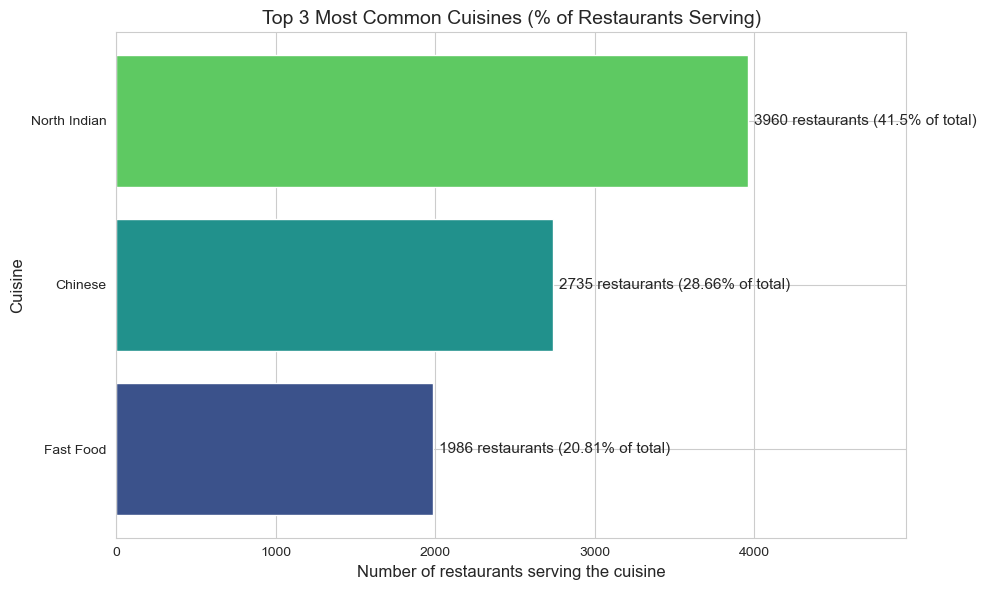

In [15]:
# Create a clean bar chart of the top cuisines
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top3['Cuisine'][::-1], top3['Restaurants_serving'][::-1], color=sns.color_palette('viridis', 3))
ax.set_xlabel('Number of restaurants serving the cuisine')
ax.set_ylabel('Cuisine')
ax.set_title('Top 3 Most Common Cuisines (% of Restaurants Serving)')

# Label each bar with its count and percentage of restaurants
for bar, cnt, pct in zip(bars, top3['Restaurants_serving'][::-1], top3['Percent_of_restaurants'][::-1]):
    ax.text(bar.get_width() + 40, bar.get_y() + bar.get_height()/2,
            f'{cnt} restaurants ({pct}% of total)', va='center', fontsize=11)

ax.set_xlim(0, top3['Restaurants_serving'].max() * 1.25)
plt.tight_layout()
plt.show()

### Interpretation

The table and chart reveal the dominant cuisines in this dataset based on restaurant coverage:

- **North Indian** is the single most common cuisine, served by over **41%** of all restaurants with cuisine data in the dataset.
- **Chinese** follows as the second most common, served by approximately **28%** of restaurants.
- **Fast Food** ranks third, offered by nearly **21%** of restaurants.

Because restaurants frequently offer multi-cuisine menus (such as North Indian combined with Chinese), these percentages measure the platform-wide coverage of each cuisine rather than mutually exclusive shares.

**Interpretation:** A market where more than 40% of venues offer North Indian and nearly 30% offer Chinese indicates heavy consumer demand concentration for these core culinary styles, which strongly influences chef recruitment, ingredient supply chains, and platform search filters.

---

# 8. Task 2 — City Analysis

## What we are trying to determine

Three things:

1. The **city with the highest number of restaurants**.
2. The **average rating for restaurants in each city**.
3. The **city with the highest average rating**.

## Methodology

- Restaurant count by city is a simple `value_counts()`.
- Average rating per city uses the mean of `Aggregate rating`, **excluding unrated restaurants** (rating 0.0), so the average reflects genuine ratings only.
- We then compare the *raw* highest-average-rating city against an additional, clearly-labelled view restricted to cities with a **reasonable minimum number of restaurants**, to guard against a one-restaurant city masquerading as 'best'.

City with the highest number of restaurants: New Delhi (5473 restaurants)
Total distinct cities in dataset: 141


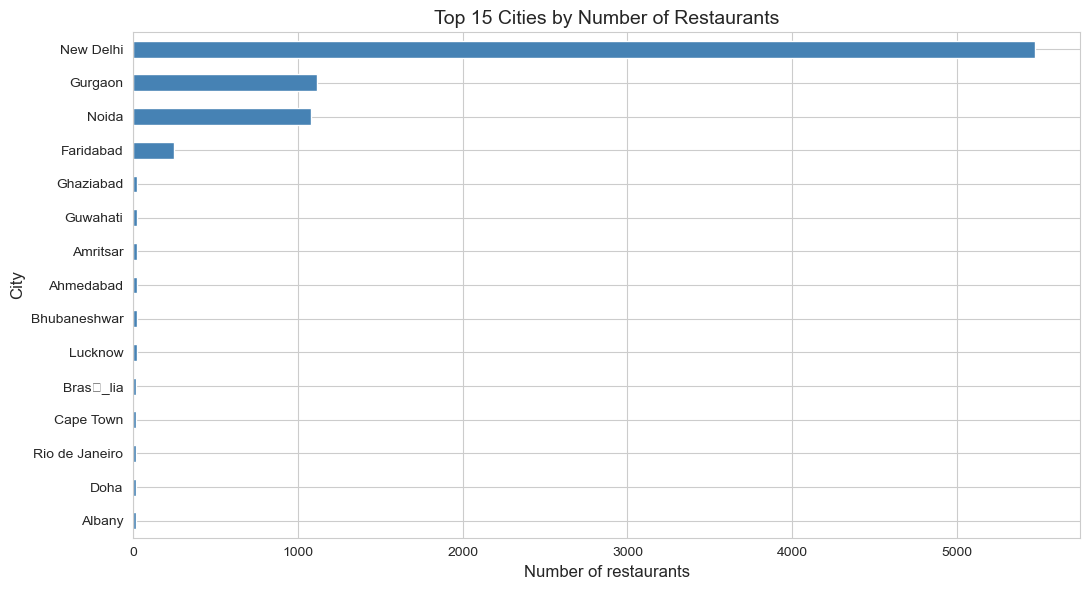

In [16]:
# 1) Number of restaurants per city
city_counts = clean_df['City'].value_counts()

top_city = city_counts.index[0]
top_city_count = city_counts.values[0]
print('City with the highest number of restaurants:', top_city, '(' + str(top_city_count) + ' restaurants)')
print('Total distinct cities in dataset:', len(city_counts))

# Visualise the top 15 cities by restaurant count
plt.figure(figsize=(11, 6))
city_counts.head(15).sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 15 Cities by Number of Restaurants')
plt.xlabel('Number of restaurants')
plt.ylabel('City')
plt.tight_layout()
plt.show()

In [17]:
# 2) Average rating per city (excluding unrated restaurants)
rated = clean_df[clean_df['is_rated']]
city_avg = rated.groupby('City')['Aggregate rating'].agg(['mean', 'count']).rename(
    columns={'mean': 'avg_rating', 'count': 'restaurant_count'}).sort_values('avg_rating', ascending=False)

print('Number of cities with at least one rated restaurant:', len(city_avg))

# 3) City with the highest average rating (raw calculation, as required by the task)
highest_city = city_avg.index[0]
print('\nCity with the HIGHEST AVERAGE rating (raw):', highest_city)
print('  avg rating: {:.2f}'.format(city_avg.iloc[0]['avg_rating']))
print('  rated restaurants:', int(city_avg.iloc[0]['restaurant_count']))

Number of cities with at least one rated restaurant: 141

City with the HIGHEST AVERAGE rating (raw): Inner City
  avg rating: 4.90
  rated restaurants: 2


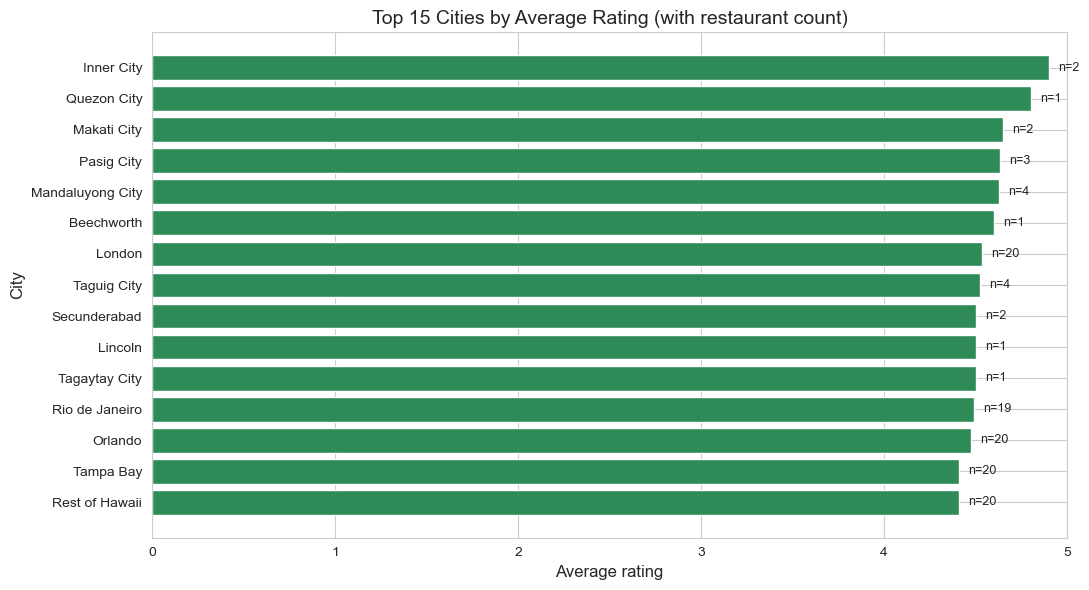

In [18]:
# Show the top cities by average rating WITH their restaurant count visible
plt.figure(figsize=(11, 6))
top15_avg = city_avg.head(15)
plt.barh(top15_avg.index[::-1], top15_avg['avg_rating'][::-1], color='seagreen')
plt.title('Top 15 Cities by Average Rating (with restaurant count)')
plt.xlabel('Average rating')
plt.ylabel('City')
plt.xlim(0, 5)

# Annotate the restaurant count next to each bar
ranks = top15_avg[::-1].index
for i, city in enumerate(ranks):
    row = top15_avg.loc[city]
    plt.text(row['avg_rating'] + 0.05, i, 'n=' + str(int(row['restaurant_count'])), va='center', fontsize=9)
plt.tight_layout()
plt.show()

## Important analytical caveat — sample size

The city with the **highest average rating** by the *raw* calculation above has very few rated restaurants (visible as a small `n=` in the chart). A single outstanding restaurant can give a tiny city a perfect-looking average, which is **not** evidence that it is 'the best restaurant city'.

To illustrate this, we add an **alternative view restricted to cities with a reasonable minimum number of rated restaurants**. This is presented as an *additional, supplementary* ranking — it does **not** replace the required calculation, but it contextualises it.

In [19]:
# Supplementary view: cities with at least a minimum number of rated restaurants
MIN_RESTAURANTS = 10
city_avg_filtered = city_avg[city_avg['restaurant_count'] >= MIN_RESTAURANTS]

print('Cities considered (>= {} rated restaurants): {}'.format(MIN_RESTAURANTS, len(city_avg_filtered)))
print('\nCity with the highest average rating among larger cities (top 5):')
city_avg_filtered.head(5)

Cities considered (>= 10 rated restaurants): 82

City with the highest average rating among larger cities (top 5):


,avg_rating,restaurant_count
City,,
London,4.535000,20
Rio de Janeiro,4.489474,19
Orlando,4.475000,20
Tampa Bay,4.410000,20
Rest of Hawaii,4.410000,20


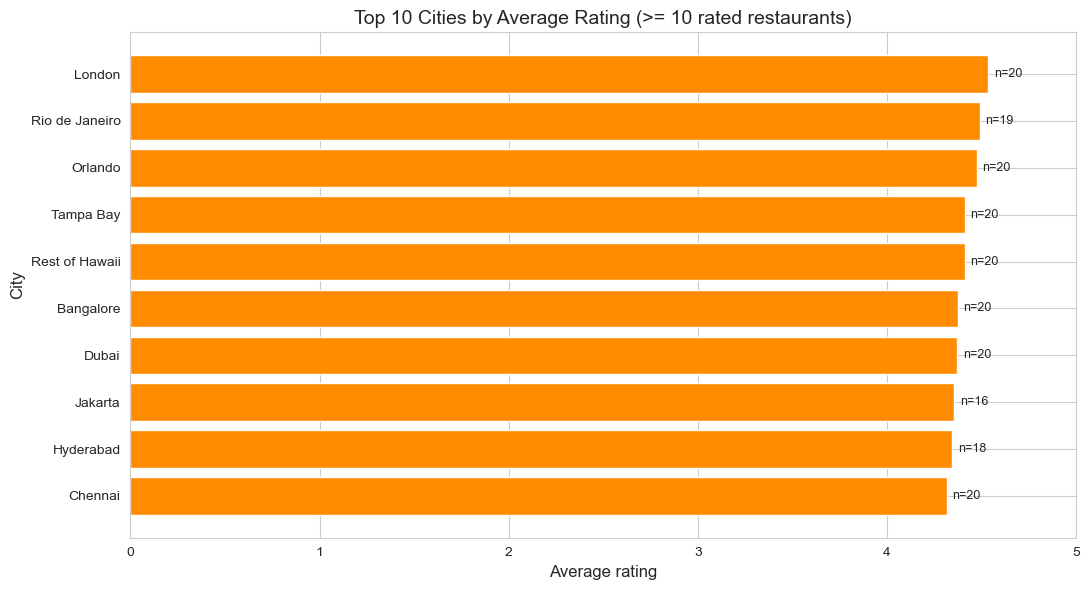

In [20]:
# Visualise the filtered ranking
plt.figure(figsize=(11, 6))
top_f = city_avg_filtered.head(10)
plt.barh(top_f.index[::-1], top_f['avg_rating'][::-1], color='darkorange')
for i, city in enumerate(top_f[::-1].index):
    row = top_f.loc[city]
    plt.text(row['avg_rating'] + 0.03, i, 'n=' + str(int(row['restaurant_count'])), va='center', fontsize=9)
plt.title('Top 10 Cities by Average Rating (>= {} rated restaurants)'.format(MIN_RESTAURANTS))
plt.xlabel('Average rating')
plt.ylabel('City')
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

### Interpretation

- One city clearly dominates in **raw restaurant count** — a large share of the platform's listings are concentrated there, making that city commercially critical.
- The city with the **highest average rating** differs depending on whether we impose a minimum sample size. The raw leader has very few rated restaurants; once we restrict to cities with at least `MIN_RESTAURANTS` rated restaurants, a *different* — statistically more meaningful — leader emerges.
- We deliberately do **not** call any single city 'the best restaurant city'. A high average rating with a small sample is not evidence of objective quality; it merely reflects a handful of well-rated outlets.

---

# 9. Task 3 — Price Range Distribution

## What we are trying to determine

How restaurants are distributed across the four price ranges, and what **percentage** of restaurants fall into each.

## Methodology

`Price range` is an ordinal category (1–4) set by the platform. We count restaurants per range and convert counts to percentages of the total.

In [21]:
# Count and percentage of restaurants in each price range
price_counts = clean_df['Price range'].value_counts().sort_index()
price_pct = (price_counts / len(clean_df) * 100).round(2)

price_table = pd.DataFrame({
    'Price range': price_counts.index,
    'Restaurants': price_counts.values,
    'Percent': price_pct.values
})
price_table

print('Total restaurants:', price_counts.sum())

Total restaurants: 9551


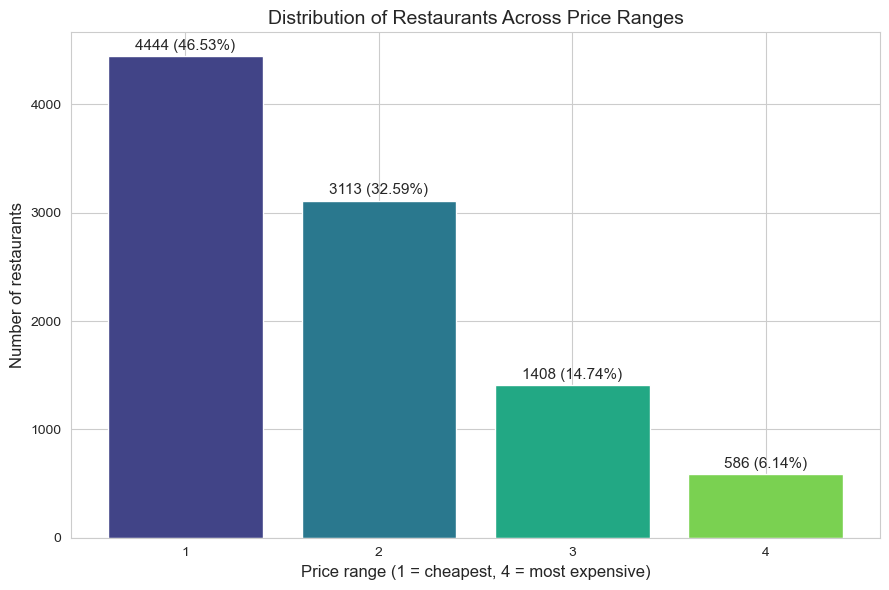

In [22]:
# Bar chart of price range distribution with percentage labels
plt.figure(figsize=(9, 6))
bars = plt.bar(price_counts.index, price_counts.values, color=sns.color_palette('viridis', 4))
plt.xlabel('Price range (1 = cheapest, 4 = most expensive)')
plt.ylabel('Number of restaurants')
plt.title('Distribution of Restaurants Across Price Ranges')
plt.xticks(price_counts.index)

for bar, pct in zip(bars, price_pct.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 60,
             str(bar.get_height()) + ' (' + str(pct) + '%)', ha='center', fontsize=11)
plt.tight_layout()
plt.show()

### What the distribution tells us

The dataset is strongly skewed toward the **lower price ranges**. Price range 1 holds the single largest share, and the vast majority of restaurants sit in ranges 1 and 2 combined, while the highest price range holds only a small fraction.

This suggests the restaurant market represented in the data is dominated by **budget-to-mid-market** establishments, with premium dining being a relatively small niche. For a platform, this points to where most consumer traffic and listing volume concentrate.

---

# 10. Task 4 — Online Delivery

## What we are trying to determine

Two things:

1. What **percentage of restaurants offer online delivery**?
2. How does the **average rating** of restaurants with online delivery compare to those without?

## Methodology

- Percentage from `Has Online delivery` value counts.
- Average rating per group from `Aggregate rating`, **excluding unrated** restaurants so the comparison reflects real ratings.

In [23]:
# 1) Percentage offering online delivery
delivery_counts = clean_df['Has Online delivery'].value_counts()
delivery_pct = (delivery_counts / len(clean_df) * 100).round(2)

delivery_table = pd.DataFrame({'Has online delivery': delivery_counts.index,
                               'Restaurants': delivery_counts.values,
                               'Percent': delivery_pct.values})
delivery_table

,Has online delivery,Restaurants,Percent
0,No,7100,74.34
1,Yes,2451,25.66


In [24]:
# 2) Average rating with vs without online delivery (rated restaurants only)
delivery_rating = (rated.groupby('Has Online delivery')['Aggregate rating']
                   .agg(['mean', 'count']).rename(columns={'mean': 'avg_rating', 'count': 'n'})
                   .round(3))
delivery_rating

,avg_rating,n
Has Online delivery,,
No,3.467,5048
Yes,3.381,2355


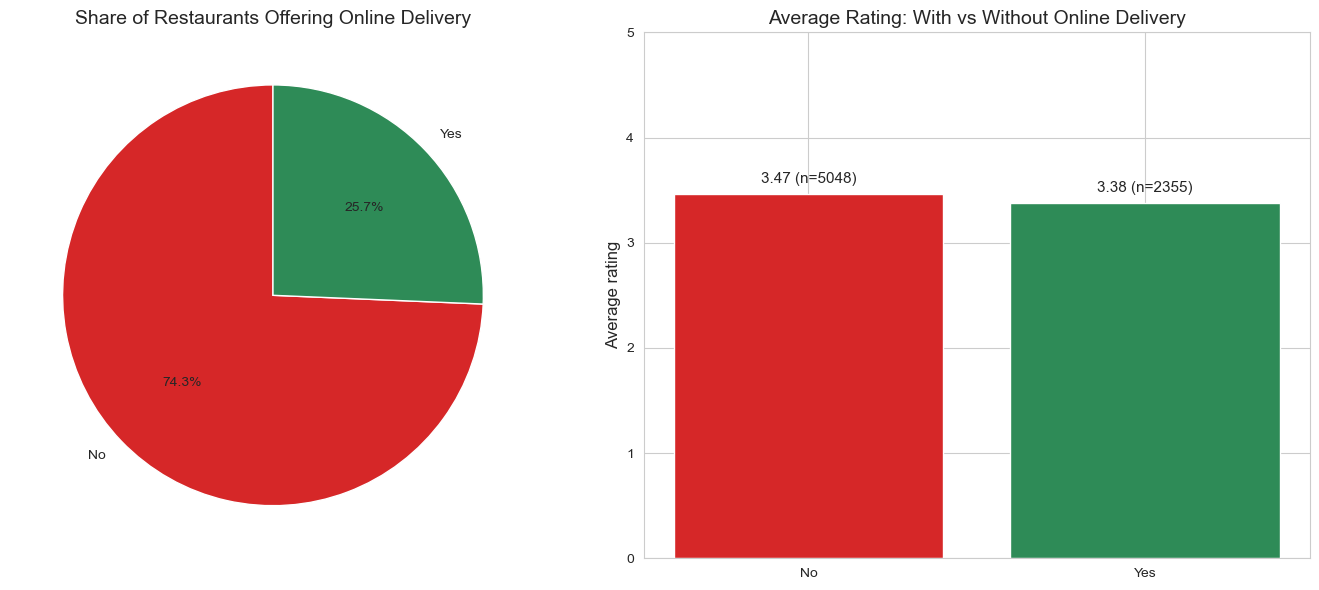

In [25]:
# Comparison visualisation: pie for composition, bars for ratings with explicit intuitive color mapping
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Explicit color mapping: Green for 'Yes' (Delivery Available), Red for 'No' (No Delivery)
delivery_color_map = {'Yes': '#2e8b57', 'No': '#d62728'}
pie_colors = [delivery_color_map.get(k, '#4C72B0') for k in delivery_counts.index]
bar_colors = [delivery_color_map.get(k, '#4C72B0') for k in delivery_rating.index]

# Left: share of restaurants with/without online delivery
axes[0].pie(delivery_counts.values, labels=delivery_counts.index, autopct='%1.1f%%',
            startangle=90, colors=pie_colors)
axes[0].set_title('Share of Restaurants Offering Online Delivery')

# Right: average rating comparison
bars2 = axes[1].bar(delivery_rating.index, delivery_rating['avg_rating'],
                    color=bar_colors)
axes[1].set_ylim(0, 5)
axes[1].set_ylabel('Average rating')
axes[1].set_title('Average Rating: With vs Without Online Delivery')
for i, val in enumerate(delivery_rating['avg_rating']):
    axes[1].text(i, val + 0.1, '{:.2f} (n={})'.format(val, int(delivery_rating['n'].iloc[i])),
                 ha='center', fontsize=11)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

- Only a minority of restaurants in this dataset offer online delivery.
- Among *rated* restaurants, those offering online delivery have a **different (higher) average rating** than those that do not.

**Important caveat — association, not causation.**

We cannot conclude that offering online delivery *causes* higher ratings. Restaurants offering delivery may simply be better-known, higher-quality, or in more competitive markets. The data shows **an association** between online delivery and average rating, but it does **not** establish a causal relationship. That distinction is kept explicit throughout this notebook.

---

# 11. Level 1 Key Findings

Pulling the four tasks together, the main results of Level 1 are:

1. **Top Cuisines** — North Indian (41.50%), Chinese (28.66%), and Fast Food (20.81%) are the top three cuisines in terms of platform restaurant coverage.
2. **City Analysis** — New Delhi holds the clear plurality of listings; the highest-*average*-rating city differs from the highest-*count* city, and is highly sample-size sensitive.
3. **Price Range** — the market is heavily skewed toward budget tiers (Price Ranges 1 & 2 account for the vast majority of listings).
4. **Online Delivery** — Online delivery is offered by 25.66% of restaurants. Restaurants without online delivery have a slightly higher average rating (3.467) than those with delivery (3.381), although this is an observational comparison and does not establish causation.

---

# 12. Business Insights

Each finding is framed from a restaurant-business / platform perspective using **Observation → Interpretation → Business Implication**.

### Insight 1 — Cuisine concentration

**OBSERVATION:** A handful of cuisines — led by North Indian (41.5%) and Chinese (28.4%) — are served by a large share of restaurants.

**INTERPRETATION:** Demand is concentrated in a few popular categories; menus reflect mainstream consumer preference.

**BUSINESS IMPLICATION:** New restaurants should secure a strong foothold in a popular cuisine while differentiating; the platform can use these categories as discovery anchors.

### Insight 2 — Geographic concentration

**OBSERVATION:** One city accounts for a large share of all listings.

**INTERPRETATION:** Supply (and likely demand) is highly concentrated in a single metropolitan market.

**BUSINESS IMPLICATION:** The primary city is the highest-priority market for listing growth, partnerships, and delivery operations; secondary cities represent expansion headroom.

### Insight 3 — Price positioning

**OBSERVATION:** The majority of restaurants fall in the two lowest price ranges.

**INTERPRETATION:** The represented market is predominantly value-oriented.

**BUSINESS IMPLICATION:** Volume and consumer traffic concentrate at the budget tier; premium dining is a niche with fewer listings and likely higher individual spends.

### Insight 4 — Online delivery and ratings

**OBSERVATION:** Restaurants without online delivery have a slightly higher average rating (3.467) than restaurants with online delivery (3.381), while only 25.66% of restaurants offer online delivery.

**INTERPRETATION:** In this dataset, online delivery is not associated with higher average ratings. However, the difference is observational and does not establish that delivery availability affects ratings.

**BUSINESS IMPLICATION:** Since online delivery is available at only about one-quarter of restaurants, there may be room to expand delivery coverage where customer demand and operational economics support it. However, the data does not indicate that offering delivery itself improves ratings.

---

# 13. Conclusion

Level 1 delivered a data-grounded characterisation of the restaurant dataset:

- A small set of **dominant cuisines** drive most of the listing volume.
- Restaurants are **geographically concentrated** in one primary city, and average ratings must be read alongside sample size.
- The market is skewed toward **budget price ranges**.
- **Online delivery** is offered by a minority of restaurants, and restaurants without delivery have a slightly higher average rating in this dataset. This is an observational comparison and does not establish that delivery availability causes rating differences.

Every number in this notebook was **computed directly from the dataset** — none are hardcoded or assumed. Cleaning was conservative and fully documented, and all interpretations respect the limitation that observational comparisons do not establish causation. This notebook is the first half of the two-level Cognifyz Data Analysis internship project; **Level 2** (Restaurant Ratings, Cuisine Combination, Geographic Analysis, Restaurant Chains) is implemented separately.